*Mathematical Foundations of Robotics · Chapter 2 — Spatial Descriptions and Transformations*

# 2.3 Homogeneous Transformations and Transform Arithmetic

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/02-spatial-descriptions-and-transformations/2.3-homogeneous-transformations.ipynb)

The general mapping ${}^{A}P = {}^{A}_{B}R\,{}^{B}P + {}^{A}P_{BORG}$ is a rotation followed by a translation. It is
correct, but chaining several such mappings quickly becomes untidy, because every step adds a translation that
must itself be rotated by every later step. This notebook packs rotation and translation into a single
$4\times4$ **homogeneous transformation matrix**, so that chains of frames become plain matrix products — the
building block of forward kinematics.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., §2.3–2.7, §2.9–2.10 |
| **Parallel reading** | Lynch & Park §3.3.1 (and §3.3.2–3.3.3, §3.4 beyond the syllabus) · Spong et al. Ch. 2 (rigid motions; homogeneous transformations) · Siciliano et al. §2.7 · Corke *RVC* Ch. 2 |
| **Lectures** | [Prof. G. C. Nandi, Lecture 15 — Spatial transformation explained in a simple way](https://www.youtube.com/watch?v=CJdCTyDpX4U) · [ThatsEngineering — Compound transformation matrices and inverse transformation matrices](https://www.youtube.com/watch?v=sm7d1A2npWA) · [Modern Robotics 3.3.1 Homogeneous transformation matrices](https://www.youtube.com/watch?v=vlb3P7arbkU) |
| **Prerequisites** | [2.2 Mappings and Operators](2.2-mappings-and-operators.ipynb) |
| **Study time** | about 3 hours |

## Learning objectives

1. Write the general mapping as a single matrix product using homogeneous coordinates, and explain why the matrix is called *homogeneous*.
2. Distinguish points ($w=1$) from free vectors ($w=0$) and transform each correctly.
3. Invert a homogeneous transform by exploiting its structure, without a general matrix inverse.
4. Compose transforms along a chain, set up **transform equations** from a transform graph, and solve them for an unknown frame.
5. Use transforms as **operators**, including rotation about an axis that does not pass through the origin.
6. Reproduce a camera-to-robot calculation around a real UR5e in MuJoCo and render the scene from the camera's own frame.

## Contents

1. [From the general mapping to a 4 × 4 matrix](#1.-From-the-general-mapping-to-a-4-×-4-matrix)
2. [Points, free vectors and the fourth coordinate](#2.-Points,-free-vectors-and-the-fourth-coordinate)
3. [Inverting a transform by using its structure](#3.-Inverting-a-transform-by-using-its-structure)
4. [Compound transformations](#4.-Compound-transformations)
5. [Transform equations and transform graphs](#5.-Transform-equations-and-transform-graphs)
6. [Transformations as operators](#6.-Transformations-as-operators)
7. [Three interpretations and computational considerations](#7.-Three-interpretations-and-computational-considerations)
8. [A real robot, a camera and a part in MuJoCo](#8.-A-real-robot,-a-camera-and-a-part-in-MuJoCo)
9. [Beyond the syllabus: twists and exponential coordinates](#9.-Beyond-the-syllabus:-twists-and-exponential-coordinates)
10. [Worked examples](#10.-Worked-examples)
11. [Summary, common mistakes and exercises](#11.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit.transforms import rotx, roty, rotz, rot_axis_angle, make_T, inv_T, transl, is_transform, orthonormalize

## 1. From the general mapping to a 4 × 4 matrix

Append a $1$ to every position vector and stack ${}^{A}_{B}R$ and ${}^{A}P_{BORG}$ into one matrix:

$$
\begin{bmatrix}{}^{A}P\\ 1\end{bmatrix}
=
\begin{bmatrix}{}^{A}_{B}R & {}^{A}P_{BORG}\\ \mathbf 0^{\mathsf T} & 1\end{bmatrix}
\begin{bmatrix}{}^{B}P\\ 1\end{bmatrix}
\qquad\Longleftrightarrow\qquad
{}^{A}P = {}^{A}_{B}T\;{}^{B}P .
$$

Multiplying out the top three rows returns ${}^{A}P = {}^{A}_{B}R\,{}^{B}P + {}^{A}P_{BORG}$; the bottom row merely
reproduces the trailing $1$. Nothing new has been assumed — the extra row and column are bookkeeping that let
**one** matrix product perform the rotation and the translation together.

> **Definition (homogeneous transformation).** The matrix
> $$ {}^{A}_{B}T = \begin{bmatrix}{}^{A}_{B}R & {}^{A}P_{BORG}\\ 0\ \ 0\ \ 0 & 1\end{bmatrix} $$
> describes the frame $\{B\}$ relative to $\{A\}$. The set of all such matrices with ${}^{A}_{B}R\in SO(3)$ is the
> **special Euclidean group** $SE(3)$; a member has $3 + 3 = 6$ independent parameters.

**Why "homogeneous"?** A rotation followed by a translation is an *affine* map, not a linear one: it does not
send the zero vector to zero. By adding a fourth coordinate we embed it in a *linear* map of one higher
dimension. The name comes from projective geometry, where $(x, y, z, w)$ and $(\lambda x, \lambda y, \lambda z, \lambda w)$
denote the same point; in robotics the last row is always $[0\ 0\ 0\ 1]$ and the scale is always $1$. (In computer
vision, the same machinery with a non-trivial last row models perspective projection.)

In [2]:
R_AB, p_AB = rotz(deg(30)), np.array([10.0, 5.0, 0.0])
T_AB = make_T(R_AB, p_AB)
display(Math(matrix_to_latex(T_AB, 4, r"{}^{A}_{B}T")))
P_B = np.array([3.0, 7.0, 0.0])
via_T = (T_AB @ np.append(P_B, 1.0))[:3]
via_Rp = R_AB @ P_B + p_AB
print("T @ [P;1]      =", via_T.round(4))
print("R @ P + p_BORG =", via_Rp.round(4), "  identical:", np.allclose(via_T, via_Rp))

<IPython.core.display.Math object>

T @ [P;1]      = [ 9.0981 12.5622  0.    ]
R @ P + p_BORG = [ 9.0981 12.5622  0.    ]   identical: True


## 2. Points, free vectors and the fourth coordinate

Positions depend on where the origin is. **Free vectors** — velocities, forces, moments, pure directions — do
not: they have no point of application for our purposes. They therefore transform with the rotation part only
(Craig §2.9):

$$
{}^{A}V = {}^{A}_{B}R\;{}^{B}V \qquad (\text{never add } {}^{A}P_{BORG}).
$$

Homogeneous coordinates handle this automatically if a free vector is given a fourth component of $0$:
$T\,[\mathbf v;\,0] = [R\mathbf v;\,0]$. A *difference of two points* is a free vector, and indeed
$[P_1;1]-[P_2;1] = [P_1-P_2;\,0]$.

| Quantity | Homogeneous form | Transforms as |
|:--|:--|:--|
| Point / position | $[x\ y\ z\ 1]^{\mathsf T}$ | $R\mathbf p + \mathbf t$ |
| Free vector (direction, velocity, force) | $[x\ y\ z\ 0]^{\mathsf T}$ | $R\mathbf v$ only |

In [3]:
v_B = np.array([1.0, 0.0, 0.0])                         # a direction (e.g. a force) written in {B}
print("as a point  (w=1):", (T_AB @ np.append(v_B, 1))[:3].round(4), " <- includes the translation: wrong for a force")
print("as a vector (w=0):", (T_AB @ np.append(v_B, 0))[:3].round(4), " <- rotation only: correct")

as a point  (w=1): [10.866  5.5    0.   ]  <- includes the translation: wrong for a force
as a vector (w=0): [0.866 0.5   0.   ]  <- rotation only: correct


## 3. Inverting a transform by using its structure

Given ${}^{A}_{B}T$, we often need ${}^{B}_{A}T = {}^{A}_{B}T^{-1}$. A general $4\times4$ inverse would work, but the
structure gives the answer directly. The rotation part is easy: ${}^{B}_{A}R = {}^{A}_{B}R^{\mathsf T}$. For the
translation part we need ${}^{B}P_{AORG}$, the origin of $\{A\}$ written in $\{B\}$. Map the origin of $\{B\}$ into
$\{B\}$ itself — it is, of course, the zero vector:

$$
{}^{B}\big({}^{A}P_{BORG}\big) = {}^{B}_{A}R\;{}^{A}P_{BORG} + {}^{B}P_{AORG} = \mathbf 0
\quad\Longrightarrow\quad
{}^{B}P_{AORG} = -\,{}^{A}_{B}R^{\mathsf T}\;{}^{A}P_{BORG}.
$$

> **Inverse of a homogeneous transform (Craig eq. 2.45).**
> $$ {}^{B}_{A}T = {}^{A}_{B}T^{-1} = \begin{bmatrix}{}^{A}_{B}R^{\mathsf T} & -{}^{A}_{B}R^{\mathsf T}\,{}^{A}P_{BORG}\\ \mathbf 0^{\mathsf T} & 1\end{bmatrix}. $$
>
> ⚠️ The inverse is **not** $T^{\mathsf T}$: only the rotation block is transposed.

The structured inverse costs one $3\times3$ transpose (free) and one matrix–vector product, and is exactly
orthonormal by construction; a general inverse costs more and introduces rounding error into $R$.

In [4]:
T_BA = inv_T(T_AB)
display(Math(matrix_to_latex(T_BA, 4, r"{}^{B}_{A}T")))
print("T_BA @ T_AB == I       :", np.allclose(T_BA @ T_AB, np.eye(4)))
print("agrees with np.linalg.inv:", np.allclose(T_BA, np.linalg.inv(T_AB)))
print("T^T is NOT the inverse :", not np.allclose(T_AB.T @ T_AB, np.eye(4)))

import timeit
n = 20000
t_struct = timeit.timeit(lambda: inv_T(T_AB), number=n) / n * 1e6
t_gen = timeit.timeit(lambda: np.linalg.inv(T_AB), number=n) / n * 1e6
print(f"structured inverse ≈ {t_struct:.1f} µs, general inverse ≈ {t_gen:.1f} µs (Python overheads dominate both)")

<IPython.core.display.Math object>

T_BA @ T_AB == I       : True
agrees with np.linalg.inv: True
T^T is NOT the inverse : True


structured inverse ≈ 6.6 µs, general inverse ≈ 5.3 µs (Python overheads dominate both)


## 4. Compound transformations

If $\{C\}$ is known relative to $\{B\}$ and $\{B\}$ relative to $\{A\}$, then
${}^{A}P = {}^{A}_{B}T\,{}^{B}P = {}^{A}_{B}T\,{}^{B}_{C}T\,{}^{C}P$ for every point, so

$$
{}^{A}_{C}T = {}^{A}_{B}T\;{}^{B}_{C}T
= \begin{bmatrix}{}^{A}_{B}R\,{}^{B}_{C}R & {}^{A}_{B}R\,{}^{B}P_{CORG} + {}^{A}P_{BORG}\\ \mathbf 0^{\mathsf T} & 1\end{bmatrix}.
$$

The block form shows what the $4\times4$ product does for us: it multiplies the rotations *and* rotates each
later origin offset into the earlier frame before adding it. A serial robot is precisely such a chain — one
transform per link — and the animation below previews Chapter 3 by building a planar two-link arm from
alternating rotations about $\hat Z$ and translations along the new $\hat X$:
${}^{0}_{2}T = R_Z(\theta_1)\,\mathrm{Trans}_X(L_1)\,R_Z(\theta_2)\,\mathrm{Trans}_X(L_2)$.

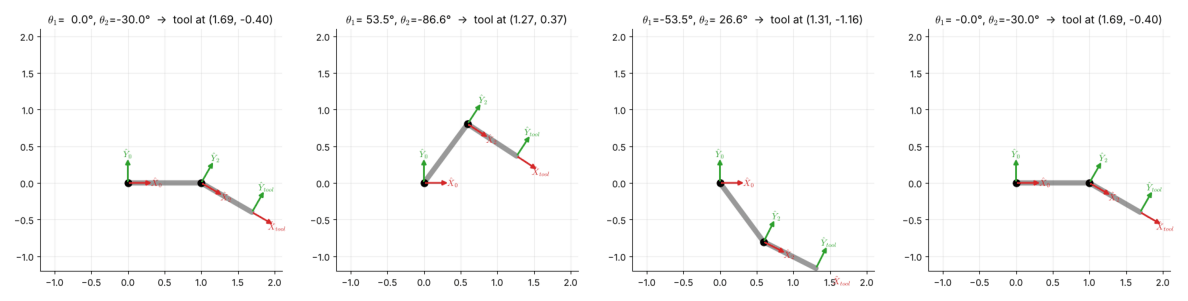

tool position at (30°, 45°): [1.0731 1.2727]  closed form: [1.0731 1.2727]


In [5]:
L1, L2 = 1.0, 0.8
RotZ = lambda t: make_T(rotz(t))

def arm_frames(t1, t2):
    T1 = RotZ(t1)                         # frame at joint 1
    T2 = T1 @ transl(L1) @ RotZ(t2)       # frame at joint 2
    T3 = T2 @ transl(L2)                  # tool frame
    return [np.eye(4), T1, T2, T3]

fig, ax = plt.subplots(figsize=(5.6, 5.0))

def update(s):
    t1, t2 = deg(60) * np.sin(2 * np.pi * s), deg(-30) + deg(70) * np.sin(4 * np.pi * s)
    Ts = arm_frames(t1, t2)
    ax.cla()
    pts = np.array([T[:2, 3] for T in Ts[1:]])
    ax.plot(pts[:, 0], pts[:, 1], "-", color="#555", lw=6, solid_capstyle="round", alpha=0.6)
    ax.plot(pts[:2, 0], pts[:2, 1], "o", color="k", ms=8)
    for name, T in zip(["0", "1", "2", "tool"], Ts):
        if name == "1":
            continue
        th = np.arctan2(T[1, 0], T[0, 0])
        draw_frame_2d(ax, th, origin=T[:2, 3], name=name, length=0.35, fontsize=10)
    ax.set_xlim(-1.2, 2.1); ax.set_ylim(-1.2, 2.1); ax.set_aspect("equal"); ax.grid(alpha=0.25)
    x, y = Ts[3][:2, 3]
    ax.set_title(rf"$\theta_1$={np.degrees(t1):5.1f}°, $\theta_2$={np.degrees(t2):5.1f}°  →  tool at ({x:.2f}, {y:.2f})")

animate(fig, update, np.linspace(0, 1, 41), interval=90, gif="assets/2.3-compound-transforms-2link.gif")
T = arm_frames(deg(30), deg(45))[-1]
print("tool position at (30°, 45°):", T[:2, 3].round(4), " closed form:",
      np.round([L1 * np.cos(deg(30)) + L2 * np.cos(deg(75)), L1 * np.sin(deg(30)) + L2 * np.sin(deg(75))], 4))

## 5. Transform equations and transform graphs

In a workcell many frames are related by known transforms, and the product of transforms around any **closed
loop** must be the identity. Craig's convention is to draw a **transform graph**: one node per frame and one
arrow per known transform, pointing from the reference frame to the described frame. Two different paths
between the same pair of nodes give a **transform equation**; for example, with the universe $\{U\}$, robot
base $\{B\}$, a table $\{T\}$, a camera $\{C\}$ and a part $\{P\}$:

$$
{}^{U}_{P}T = {}^{U}_{B}T\;{}^{B}_{P}T = {}^{U}_{C}T\;{}^{C}_{P}T .
$$

If the camera measures ${}^{C}_{P}T$ and the workcell is calibrated (${}^{U}_{B}T$ and ${}^{U}_{C}T$ are known), the
unknown ${}^{B}_{P}T$ — where the robot must go — is isolated by pre-multiplying with the inverse:

$$
{}^{B}_{P}T = {}^{U}_{B}T^{-1}\;{}^{U}_{C}T\;{}^{C}_{P}T .
$$

A practical recipe: **traverse the graph from the "from" node to the "to" node; multiply by $T$ when you travel
along an arrow and by $T^{-1}$ when you travel against it.**

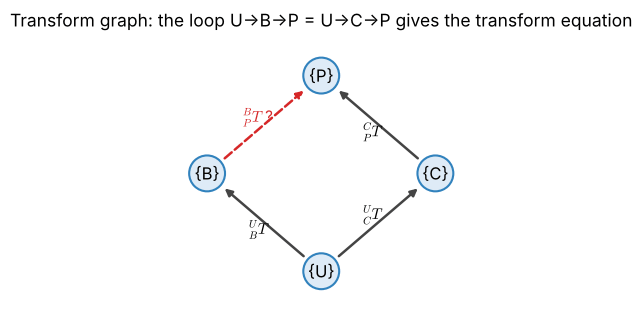

In [6]:
def draw_transform_graph(nodes, edges, unknown=None, ax=None):
    """nodes: {name: (x, y)}; edges: list of (from, to, label). Arrow from reference to described frame."""
    ax = ax or plt.subplots(figsize=(6, 3.6))[1]
    for n, (x, y) in nodes.items():
        ax.add_patch(plt.Circle((x, y), 0.22, color="#deebf7", ec="#3182bd", lw=1.5, zorder=3))
        ax.text(x, y, f"{{{n}}}", ha="center", va="center", fontsize=12, zorder=4)
    for a, b, lab in edges + ([unknown] if unknown else []):
        (x0, y0), (x1, y1) = np.array(nodes[a]), np.array(nodes[b])
        d = np.array([x1 - x0, y1 - y0]); d /= np.linalg.norm(d)
        s, e = np.array([x0, y0]) + 0.25 * d, np.array([x1, y1]) - 0.25 * d
        unk = unknown is not None and (a, b, lab) == unknown
        ax.annotate("", xy=e, xytext=s, arrowprops=dict(arrowstyle="-|>", lw=1.8,
                    color="#d62728" if unk else "#444", linestyle="--" if unk else "-"))
        m = (s + e) / 2 + 0.12 * np.array([-d[1], d[0]])
        ax.text(*m, lab, ha="center", va="center", fontsize=11, color="#d62728" if unk else "k")
    ax.set_aspect("equal"); ax.set_axis_off()
    xs, ys = zip(*nodes.values()); ax.set_xlim(min(xs) - 0.5, max(xs) + 0.5); ax.set_ylim(min(ys) - 0.5, max(ys) + 0.5)
    return ax

nodes = {"U": (0, 0), "B": (-1.4, 1.2), "C": (1.4, 1.2), "P": (0, 2.4)}
edges = [("U", "B", r"${}^{U}_{B}T$"), ("U", "C", r"${}^{U}_{C}T$"), ("C", "P", r"${}^{C}_{P}T$")]
ax = draw_transform_graph(nodes, edges, unknown=("B", "P", r"${}^{B}_{P}T$ ?"))
ax.set_title("Transform graph: the loop U→B→P = U→C→P gives the transform equation")
plt.show()

## 6. Transformations as operators

Like a rotation matrix, a homogeneous transform can also act as an **operator** that moves a point within one
frame: ${}^{A}P_2 = T\,{}^{A}P_1$. The elementary operators are

$$
\mathrm{Trans}(\mathbf d) = \begin{bmatrix} I & \mathbf d\\ \mathbf 0^{\mathsf T} & 1\end{bmatrix},\qquad
\mathrm{Rot}(\hat K,\theta) = \begin{bmatrix} R_K(\theta) & \mathbf 0\\ \mathbf 0^{\mathsf T} & 1\end{bmatrix}.
$$

**Rotation about an axis that does not pass through the origin.** To rotate by $\theta$ about an axis $\hat K$
through a point $\mathbf c$: translate $\mathbf c$ to the origin, rotate, and translate back,

$$
T = \mathrm{Trans}(\mathbf c)\;\mathrm{Rot}(\hat K,\theta)\;\mathrm{Trans}(-\mathbf c).
$$

The operator is applied right-to-left (it acts on a point placed on its right). The figure rotates a square
by $90^\circ$ about the vertical axis through $\mathbf c = (1.5,\ 1,\ 0)$: the point $\mathbf c$ itself does not move.

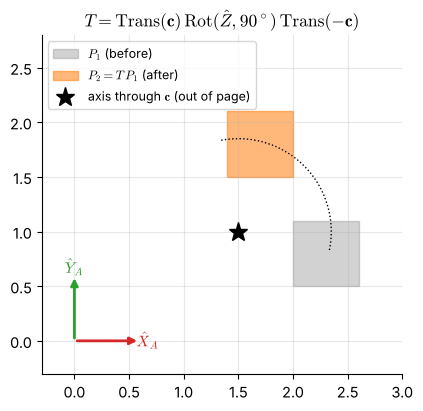

c is a fixed point of T: True


In [7]:
c = np.array([1.5, 1.0, 0.0])
T_op = transl(*c) @ make_T(rotz(deg(90))) @ transl(*(-c))
square = np.array([[2.0, 0.5, 0, 1], [2.6, 0.5, 0, 1], [2.6, 1.1, 0, 1], [2.0, 1.1, 0, 1], [2.0, 0.5, 0, 1]]).T
moved = T_op @ square
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.fill(*square[:2], alpha=0.35, color="grey", label=r"$P_1$ (before)")
ax.fill(*moved[:2], alpha=0.55, color="#ff7f0e", label=r"$P_2 = T\,P_1$ (after)")
ax.plot(*c[:2], "k*", ms=14, label=r"axis through $\mathbf{c}$ (out of page)")
ang = np.linspace(-0.2, np.pi / 2 + 0.2, 40); ax.plot(c[0] + 0.85 * np.cos(ang), c[1] + 0.85 * np.sin(ang), "k:", lw=1)
draw_frame_2d(ax, 0, name="A", length=0.6)
ax.set_xlim(-0.3, 3.0); ax.set_ylim(-0.3, 2.8); ax.set_aspect("equal"); ax.legend(loc="upper left", fontsize=9)
ax.set_title(r"$T=\mathrm{Trans}(\mathbf{c})\,\mathrm{Rot}(\hat Z,90^\circ)\,\mathrm{Trans}(-\mathbf{c})$")
plt.show()
print("c is a fixed point of T:", np.allclose(T_op @ np.append(c, 1), np.append(c, 1)))

## 7. Three interpretations and computational considerations

| Interpretation | Formula | Meaning |
|:--|:--|:--|
| **Description** of a frame | ${}^{A}_{B}T$ | columns 1–3: axes of $\{B\}$ in $\{A\}$; column 4: its origin |
| **Transform mapping** | ${}^{A}P = {}^{A}_{B}T\,{}^{B}P$ | the same point, re-expressed in another frame |
| **Transform operator** | $P_2 = T\,P_1$ | the point is moved within one frame |

**Computational considerations (Craig §2.10).**

* Multiply transforms **by blocks** — one $3\times3$ product plus one rotated vector — rather than as dense
  $4\times4$ matrices: the zeros and ones cost nothing. A dense $4\times4$ product needs 64 multiplications; the
  block form needs $27 + 9 = 36$.
* **Invert with the transpose formula**, never with a general inverse.
* When many points are mapped through a fixed chain, **multiply the chain once** and reuse the result.
* Long products **accumulate rounding error**, and $R$ slowly stops being orthonormal. Re-orthonormalise from
  time to time (for example with the SVD, as `rgkit.transforms.orthonormalize` does), or store orientations as
  quaternions and renormalise them (Section 2.5). The experiment below shows the drift in single precision.

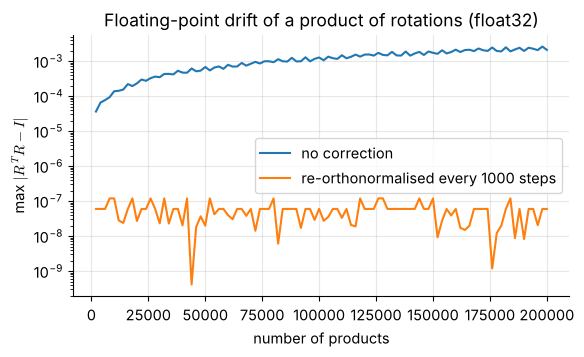

In [8]:
step32 = rot_axis_angle([1, 2, 3], 1e-3).astype(np.float32)
R32, R32_fixed = np.eye(3, dtype=np.float32), np.eye(3, dtype=np.float32)
errs, errs_fixed, ks = [], [], []
for k in range(1, 200_001):
    R32 = R32 @ step32
    R32_fixed = R32_fixed @ step32
    if k % 1000 == 0:
        R32_fixed = orthonormalize(R32_fixed).astype(np.float32)
    if k % 2000 == 0:
        ks.append(k)
        errs.append(np.abs(R32.T @ R32 - np.eye(3)).max())
        errs_fixed.append(np.abs(R32_fixed.T @ R32_fixed - np.eye(3)).max())
plt.figure(figsize=(6.4, 3.4))
plt.semilogy(ks, errs, label="no correction")
plt.semilogy(ks, errs_fixed, label="re-orthonormalised every 1000 steps")
plt.xlabel("number of products"); plt.ylabel(r"max $|R^TR - I|$"); plt.legend()
plt.title("Floating-point drift of a product of rotations (float32)"); plt.show()

## 8. A real robot, a camera and a part in MuJoCo

We now build the workcell of Section 5 in MuJoCo around a **real robot**: the Universal Robots **UR5e** from
[MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie) (downloaded on first use, see
[docs/MUJOCO.md](../../docs/MUJOCO.md)). MJCF's `<attach>` element mounts the manufacturer's model on a body of
our own model, so the arm inherits whatever pose we give that body. Four frames matter:

* $\{U\}$ — the universe frame, MuJoCo's world frame;
* $\{B\}$ — the **mount** frame that an installer would define on the table (the robot's "base" in our drawings);
* $\{C\}$ — a camera. MJCF cameras, like OpenGL cameras, **look along their own $-\hat Z$ axis**, with $\hat Y$ up in the image;
* $\{P\}$ — a part lying on the table.

We read all poses from the simulator, form the measurement ${}^{C}_{P}T$ that a perfect camera would report, and
compute where the part is relative to the robot's base in two ways — directly from MuJoCo, and from the
transform equation of Section 5. A last line asks the question every pick-and-place program starts from:
*where is the part relative to the tool right now?*

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Transform equation agrees with MuJoCo's poses: True
Part's depth in front of the camera (along -Z_C): 1.208 m

The UR5e's own base-link frame relative to the mount frame {B}: rotation = Rz(180°)? True  origin = [0. 0. 0.]
Tool (flange) position in the base frame {B}: [-0.134  0.492  0.488] m
Part position relative to the tool, ^T P_ORG: [0.642 0.372 0.438] m   (distance 0.862 m)


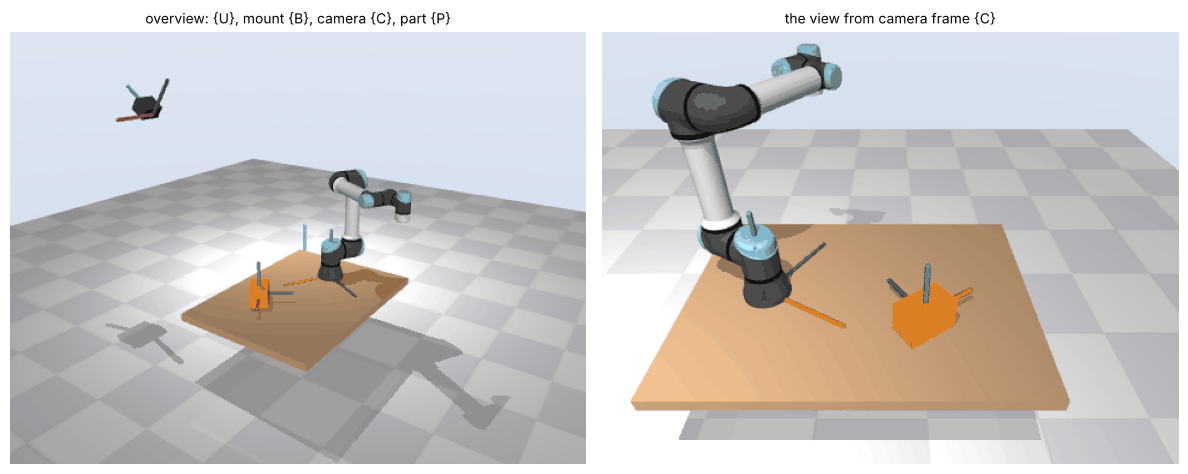

In [9]:
from rgkit import mujoco_utils as mju, robots
import mujoco

ur5e_dir = robots.fetch("ur5e")                 # the real UR5e model: downloaded once, then cached
home = [-1.5708, -1.5708, 1.5708, -1.5708, -1.5708, 0.0]    # the manufacturer's "home" joint angles (rad)

xml = f"""
<mujoco model="workcell">
  <compiler angle="degree"/>
  <option integrator="implicitfast"/>
  {mju.scene_assets()}
  <asset><model name="ur5e" file="{ur5e_dir}/ur5e.xml"/></asset>
  <worldbody>
    {mju.floor(z=0.0, size=3)}
    {mju.frame_axes_geoms(length=0.4, radius=0.01, alpha=0.5, prefix="U_")}
    <geom name="table" type="box" pos="0.9 0.6 0.35" size="0.55 0.4 0.02" rgba="0.75 0.6 0.45 1"/>
    <body name="mount" pos="0.6 0.6 0.37" euler="0 0 -30">
      {mju.frame_axes_geoms(length=0.3, radius=0.008, prefix="B_")}
      <attach model="ur5e" body="base" prefix="ur5e/"/>
    </body>
    <body name="part" pos="1.1 0.45 0.42" euler="0 0 35">
      {mju.frame_axes_geoms(length=0.18, radius=0.008, prefix="P_")}
      <geom type="box" size="0.08 0.05 0.05" rgba="0.95 0.55 0.15 1"/>
    </body>
    <body name="camera_mount" pos="1.0 -0.4 1.3" xyaxes="1 0 0 0 0.6 0.8">
      {mju.frame_axes_geoms(length=0.25, radius=0.01, prefix="C_")}
      <camera name="cam" fovy="55"/>
      <geom type="box" size="0.06 0.04 0.05" pos="0 0 0.06" rgba="0.2 0.2 0.2 1"/>
    </body>
  </worldbody>
</mujoco>"""
model, data = mju.load(xml)
data.qpos[:] = home
mujoco.mj_forward(model, data)

def T_body(name):
    return make_T(data.body(name).xmat.reshape(3, 3), data.body(name).xpos)

tool = data.site("ur5e/attachment_site")        # the robot's flange (tool) frame
T_UB, T_UC, T_UP = T_body("mount"), T_body("camera_mount"), T_body("part")
T_UR = T_body("ur5e/base")                      # the manufacturer's own base-link frame
T_UT = make_T(tool.xmat.reshape(3, 3), tool.xpos)

T_CP = inv_T(T_UC) @ T_UP                       # what an ideal camera would measure
T_BP_equation = inv_T(T_UB) @ T_UC @ T_CP       # the transform equation of Section 5
T_BP_direct = inv_T(T_UB) @ T_UP
display(Math(matrix_to_latex(T_CP, 3, r"{}^{C}_{P}T\ (\text{measured})")))
display(Math(matrix_to_latex(T_BP_equation, 3, r"{}^{B}_{P}T = {}^{U}_{B}T^{-1}\,{}^{U}_{C}T\,{}^{C}_{P}T")))
print("Transform equation agrees with MuJoCo's poses:", np.allclose(T_BP_equation, T_BP_direct))
print("Part's depth in front of the camera (along -Z_C):", (-T_CP[2, 3]).round(3), "m")

T_BR = inv_T(T_UB) @ T_UR
print("\nThe UR5e's own base-link frame relative to the mount frame {B}: rotation = Rz(180°)?",
      np.allclose(T_BR[:3, :3], rotz(np.pi)), " origin =", T_BR[:3, 3].round(6))
T_BT = inv_T(T_UB) @ T_UT
T_TP = inv_T(T_UT) @ T_UP
print("Tool (flange) position in the base frame {B}:", T_BT[:3, 3].round(3), "m")
print("Part position relative to the tool, ^T P_ORG:", T_TP[:3, 3].round(3), "m   (distance",
      np.linalg.norm(T_TP[:3, 3]).round(3), "m)")

overview = mju.render(model, data, camera=dict(azimuth=215, elevation=-22, distance=3.0, lookat=(0.8, 0.5, 0.6)))
cam_view = mju.render(model, data, camera="cam")
filmstrip([overview, cam_view], ["overview: {U}, mount {B}, camera {C}, part {P}", "the view from camera frame {C}"])

The robot now "knows" where the part is in its own base frame, although it was only ever seen by the camera.
This calculation — chaining a calibration transform with a measurement — is the everyday business of a robot
cell. Two real-world details are worth remembering. First, the manufacturer's base-link frame is **rotated
$180^\circ$ about $\hat Z$** relative to the mount frame we defined, so a position quoted by the robot's controller in
"base coordinates" differs from a position in our $\{B\}$ by a sign flip in $x$ and $y$ — always check which frame
a number refers to. Second, the final line, ${}^{T}P_{ORG}$ of the part, is the displacement the arm must still
produce; finding the joint angles that produce it is the inverse-kinematics problem of Chapter 4.

## 9. Beyond the syllabus: twists and exponential coordinates

Lynch & Park describe every rigid motion as a **screw motion**: a rotation about some axis combined with a
translation along that same axis (Chasles' theorem). A unit **screw axis** $\mathcal S = (\boldsymbol\omega, \mathbf v)$
moved through a distance $\theta$ produces the transform

$$
T = e^{[\mathcal S]\theta},\qquad
[\mathcal S] = \begin{bmatrix}[\boldsymbol\omega]_\times & \mathbf v\\ \mathbf 0^{\mathsf T} & 0\end{bmatrix}\in se(3),
$$

and the matrix logarithm recovers $\mathcal S\theta$ from $T$. These **exponential coordinates** give the
*product-of-exponentials* formula for forward kinematics (Lynch & Park Ch. 4), an alternative to the
Denavit–Hartenberg convention that Chapter 3 will compare with Craig's method. The cell below checks numerically
that the matrix exponential of a pure-rotation screw about an axis through $\mathbf c$ reproduces the operator
$\mathrm{Trans}(\mathbf c)\mathrm{Rot}(\hat Z,\theta)\mathrm{Trans}(-\mathbf c)$ of Section 6 (for a rotation axis
through $\mathbf c$, $\mathbf v = -\boldsymbol\omega\times\mathbf c$).

In [10]:
from scipy.linalg import expm, logm
from rgkit.transforms import skew
w = np.array([0.0, 0.0, 1.0]); v = -np.cross(w, c)
S_hat = np.zeros((4, 4)); S_hat[:3, :3], S_hat[:3, 3] = skew(w), v
print("expm([S] θ) equals Trans(c) Rot(Z, 90°) Trans(-c):", np.allclose(expm(S_hat * deg(90)), T_op))
print("logm recovers [S] θ:", np.allclose(np.real(logm(T_op)), S_hat * deg(90)))

expm([S] θ) equals Trans(c) Rot(Z, 90°) Trans(-c): True
logm recovers [S] θ: True


## 10. Worked examples

**Example 2.3.1 (Craig Example 2.4 — a transform operator).** Rotate ${}^{A}P_1 = (3,\ 7,\ 0)$ by $30^\circ$ about
$\hat Z$ and then translate it 10 units along $\hat X_A$ and 5 units along $\hat Y_A$. Find ${}^{A}P_2$.

*Solution.* The operator is $T = \begin{bmatrix}R_Z(30^\circ) & (10,5,0)^{\mathsf T}\\ \mathbf 0^{\mathsf T}&1\end{bmatrix}$, the
same matrix as the mapping of Example 2.2.2, and ${}^{A}P_2 = (9.098,\ 12.562,\ 0)$. Once again one matrix plays
two roles.

**Example 2.3.2 — inverse by structure.** Invert
$T = \begin{bmatrix}0&-1&0&2\\1&0&0&3\\0&0&1&5\\0&0&0&1\end{bmatrix}$.

*Solution.* $R^{\mathsf T} = \begin{bmatrix}0&1&0\\-1&0&0\\0&0&1\end{bmatrix}$ and
$-R^{\mathsf T}\mathbf p = -(3,\,-2,\,5) = (-3,\ 2,\ -5)$, so
$T^{-1} = \begin{bmatrix}0&1&0&-3\\-1&0&0&2\\0&0&1&-5\\0&0&0&1\end{bmatrix}$.

**Example 2.3.3 — where is the tool?** A robot base $\{B\}$ sees a station $\{S\}$ at
${}^{B}_{S}T = \mathrm{Trans}(1,0,0)$. Its wrist is at ${}^{B}_{W}T$ with rotation $R_Z(90^\circ)$ and origin
$(0.5,\ 0.5,\ 0.3)$, and the tool is ${}^{W}_{T}T = \mathrm{Trans}(0,0,0.1)$. Find ${}^{S}_{T}T$, the tool relative
to the station.

*Solution.* Travel $S\to B$ (against the arrow: inverse), $B\to W$, $W\to T$:
${}^{S}_{T}T = {}^{B}_{S}T^{-1}\,{}^{B}_{W}T\,{}^{W}_{T}T$. The tool offset $(0,0,0.1)$ lies along $\hat Z_W$, which
$R_Z(90^\circ)$ leaves unchanged, so the wrist-plus-tool origin is $(0.5,\ 0.5,\ 0.4)$; subtracting the station
offset gives rotation $R_Z(90^\circ)$ and origin $(-0.5,\ 0.5,\ 0.4)$.

**Example 2.3.4 — mapping and inverse.** $\{B\}$ is rotated $90^\circ$ about $\hat Z_A$ with origin $(1,2,0)$.
(a) Find ${}^{A}P$ for ${}^{B}P = (1,0,0)$. (b) Write ${}^{B}_{A}T$.

*Solution.* (a) $(0,1,0) + (1,2,0) = (1,3,0)$. (b) $R^{\mathsf T} = R_Z(-90^\circ)$ and
$-R^{\mathsf T}\mathbf p = -(2,\,-1,\,0) = (-2,\ 1,\ 0)$. Check: ${}^{B}_{A}T\,(1,3,0,1)^{\mathsf T} = (1,0,0,1)^{\mathsf T}$. ✓

In [11]:
print("Ex 2.3.1:", (make_T(rotz(deg(30)), [10, 5, 0]) @ [3, 7, 0, 1])[:3].round(3))
T = np.array([[0, -1, 0, 2], [1, 0, 0, 3], [0, 0, 1, 5], [0, 0, 0, 1]], float)
print("Ex 2.3.2:\n", inv_T(T) + 0.0)
T_ST = inv_T(transl(1, 0, 0)) @ make_T(rotz(deg(90)), [0.5, 0.5, 0.3]) @ transl(0, 0, 0.1)
print("Ex 2.3.3: rotation = Rz(90)?", np.allclose(T_ST[:3, :3], rotz(deg(90))), "  origin =", T_ST[:3, 3].round(4))
T_AB = make_T(rotz(deg(90)), [1, 2, 0])
print("Ex 2.3.4: (a)", (T_AB @ [1, 0, 0, 1])[:3].round(4), "  (b) p =", inv_T(T_AB)[:3, 3].round(4),
      "  check:", (inv_T(T_AB) @ [1, 3, 0, 1])[:3].round(4))

Ex 2.3.1: [ 9.098 12.562  0.   ]
Ex 2.3.2:
 [[ 0.  1.  0. -3.]
 [-1.  0.  0.  2.]
 [ 0.  0.  1. -5.]
 [ 0.  0.  0.  1.]]
Ex 2.3.3: rotation = Rz(90)? True   origin = [-0.5  0.5  0.4]
Ex 2.3.4: (a) [1. 3. 0.]   (b) p = [-2.  1.  0.]   check: [1. 0. 0.]


## 11. Summary

| Result | Formula |
|:--|:--|
| Homogeneous transform | ${}^{A}_{B}T = \begin{bmatrix}{}^{A}_{B}R & {}^{A}P_{BORG}\\ \mathbf 0^{\mathsf T}&1\end{bmatrix}\in SE(3)$, 6 DOF |
| Mapping | ${}^{A}P = {}^{A}_{B}T\,{}^{B}P$ with $P = [x\ y\ z\ 1]^{\mathsf T}$ |
| Free vectors | fourth coordinate $0$: only $R$ acts |
| Inverse | $\begin{bmatrix}R^{\mathsf T} & -R^{\mathsf T}\mathbf p\\ \mathbf 0^{\mathsf T}&1\end{bmatrix}$ — *not* $T^{\mathsf T}$ |
| Compound | ${}^{A}_{C}T = {}^{A}_{B}T\,{}^{B}_{C}T$ |
| Transform equation | product around a closed loop $= I$; travel against an arrow ⇒ use $T^{-1}$ |
| Rotation about an offset axis | $\mathrm{Trans}(\mathbf c)\,\mathrm{Rot}(\hat K,\theta)\,\mathrm{Trans}(-\mathbf c)$ |

### Common mistakes

* Inverting a transform by transposing the whole $4\times4$ matrix.
* Transforming a free vector (a force, a velocity, a direction) with the translation included.
* Writing a transform equation in the wrong order — check that adjacent indices cancel.
* Forgetting that MuJoCo (and OpenGL) cameras look along their **$-\hat Z$** axis.

## Exercises

**2.3.1** Show that the product of two members of $SE(3)$ is again in $SE(3)$, and that
$(T_1T_2)^{-1} = T_2^{-1}T_1^{-1}$.

<details><summary>Answer</summary>

The rotation block of $T_1T_2$ is $R_1R_2\in SO(3)$ and the last row is $[0\ 0\ 0\ 1]$. The inverse identity
holds for any invertible matrices: $(T_1T_2)(T_2^{-1}T_1^{-1}) = I$.
</details>

**2.3.2** Frame $\{B\}$ is rotated $-90^\circ$ about $\hat X_A$ and translated by $(0,\ 0,\ 2)$. A force
${}^{B}F = (0,\ 0,\ -10)$ N acts at the point ${}^{B}P = (1,\ 0,\ 0)$. Find ${}^{A}F$ and ${}^{A}P$.

<details><summary>Answer</summary>

$R_X(-90^\circ) = \begin{bmatrix}1&0&0\\0&0&1\\0&-1&0\end{bmatrix}$. ${}^{A}F = R\,{}^{B}F = (0,\ -10,\ 0)$ — no
translation. ${}^{A}P = R\,{}^{B}P + (0,0,2) = (1,\ 0,\ 2)$.
</details>

**2.3.3** In the transform graph of Section 5 a second camera $\{D\}$ is added with known ${}^{U}_{D}T$, and it
measures ${}^{D}_{P}T$. Write two expressions for ${}^{C}_{D}T$ (one using the part, one using the universe frame)
and explain how comparing them could be used to **check a calibration**.

<details><summary>Answer</summary>

${}^{C}_{D}T = {}^{U}_{C}T^{-1}\,{}^{U}_{D}T$ and ${}^{C}_{D}T = {}^{C}_{P}T\,{}^{D}_{P}T^{-1}$. If the calibration
and measurements are perfect the two agree; the size of their difference measures the calibration error.
</details>

**2.3.4** Derive the operator that rotates points by $\theta$ about the line through $\mathbf c = (0, 1, 0)$
parallel to $\hat X$, and apply it with $\theta = 90^\circ$ to the origin.

<details><summary>Answer</summary>

$T = \mathrm{Trans}(\mathbf c)\,\mathrm{Rot}(\hat X, 90^\circ)\,\mathrm{Trans}(-\mathbf c)$.
$\mathrm{Trans}(-\mathbf c)\,\mathbf 0 = (0,-1,0)$; $R_X(90^\circ)(0,-1,0) = (0,0,-1)$; adding $\mathbf c$ gives $(0,\ 1,\ -1)$.
</details>

**2.3.5** (*MuJoCo*) Move the camera in Section 8 to `pos="1.0 0.6 1.6"` looking straight down
(`xyaxes="1 0 0 0 1 0"`). Predict ${}^{C}_{P}T$ by hand before running the cell, then compare.

<details><summary>Answer</summary>

With $R = I$ the camera looks along world $-\hat Z$. ${}^{C}_{P}T$ has rotation $R_Z(35^\circ)$ and origin
$(1.1-1.0,\ 0.55-0.6,\ 0.42-1.6) = (0.10,\ -0.05,\ -1.18)$.
</details>

## Further reading and lectures

* Craig §2.3–2.7, §2.9–2.10; Lynch & Park §3.3 (and §3.4 for wrenches); Spong et al. Ch. 2; Siciliano et al. §2.7.
* Video: [Prof. G. C. Nandi, Lecture 15 — Spatial transformation explained in a simple way](https://www.youtube.com/watch?v=CJdCTyDpX4U); [ThatsEngineering — Compound transformation matrices and inverse transformation matrices](https://www.youtube.com/watch?v=sm7d1A2npWA); [Modern Robotics 3.3.1 Homogeneous transformation matrices](https://www.youtube.com/watch?v=vlb3P7arbkU); beyond the syllabus: [Modern Robotics 3.3.2 Twists (part 1)](https://www.youtube.com/watch?v=mvGZtO_ruj0), [Modern Robotics 3.3.2 Twists (part 2)](https://www.youtube.com/watch?v=VTv0qmLNvjg), [Modern Robotics 3.3.3 Exponential coordinates of rigid-body motion](https://www.youtube.com/watch?v=1jYMvm1U2D0), [Modern Robotics 3.4 Wrenches](https://www.youtube.com/watch?v=0wsYPJPGtKE).
* MuJoCo documentation: [cameras](https://mujoco.readthedocs.io/en/stable/XMLreference.html#body-camera).

---

[← 2.2 Mappings and Operators](2.2-mappings-and-operators.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md) &nbsp;·&nbsp; [2.4 Fixed Angles and Euler Angles →](2.4-fixed-angles-and-euler-angles.ipynb)